# Hassaan (Data Lead) - Penn-Fudan to YOLO format + Augmentation Ablation
**CS-320 ANN project: Pedestrian Detection, original YOLO vs modern YOLO**

This ONE notebook does all of Hassaan's work, from start to the GitHub push:

| Step | What we do |
|---|---|
| 1 | Download the Penn-Fudan dataset and look at it |
| 2 | Read the annotation text files |
| 3 | Convert boxes to YOLO format (x_center, y_center, w, h, all between 0 and 1) |
| 4 | Cross-check the boxes against the mask images |
| 5 | Split into train / val / test (70 / 15 / 15, seed 42) |
| 6 | Create the `images/` + `labels/` folders and `data.yaml` |
| 7 | Quality checks (12 checks) |
| 8 | Dataset statistics and plots |
| 9 | Draw the saved labels on images to check them by eye |
| 10 | **Ablation: with vs without data augmentation** (modern YOLO, 3 seeds) |
| 11 | Save everything and push to GitHub |

**How to run:** Runtime -> Change runtime type -> **T4 GPU**, then Runtime -> Run all. Training takes about 25-30 minutes.
The last cell asks for a GitHub token (typed hidden), so it will wait for you.

## Step 0: Setup

In [1]:
# import the libraries we need
import os, re, shutil, json, hashlib, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# same seed everywhere so that results can be repeated
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

RAW_DIR  = '/content/PennFudanPed'     # the original dataset (we download it)
DATA_DIR = '/content/PennFudanYOLO'    # the YOLO-format dataset (we create it)
OUT_DIR  = '/content/hassaan_outputs'  # small result files that we will push to GitHub

os.makedirs(OUT_DIR + '/figures', exist_ok=True)
print('Setup done')

Setup done


## Step 1: Download the dataset and look at it
Penn-Fudan has 170 images. 96 are from around the University of Pennsylvania (`PennPed...`) and 74 from Fudan University (`FudanPed...`).
Each image has a mask (one number per pedestrian) and an annotation text file (the boxes).

In [2]:
!wget -q https://www.cis.upenn.edu/~jshi/ped_html/PennFudanPed.zip -O /content/PennFudanPed.zip
!unzip -q -o /content/PennFudanPed.zip -d /content/

In [3]:
print('Folders inside the dataset:', os.listdir(RAW_DIR))

images = sorted(os.listdir(RAW_DIR + '/PNGImages'))
masks  = sorted(os.listdir(RAW_DIR + '/PedMasks'))
annots = sorted(os.listdir(RAW_DIR + '/Annotation'))

print('Number of images          :', len(images))
print('Number of masks           :', len(masks))
print('Number of annotation files:', len(annots))
print('Fudan images:', sum(f.startswith('Fudan') for f in images))
print('Penn  images:', sum(f.startswith('Penn') for f in images))

Folders inside the dataset: ['readme.txt', 'PedMasks', 'added-object-list.txt', 'Annotation', 'PNGImages']
Number of images          : 170
Number of masks           : 170
Number of annotation files: 170
Fudan images: 74
Penn  images: 96


Image size (width, height): (425, 369)
Mask values (0 = background, 1,2,3.. = each pedestrian): [0 1 2 3 4 5 6]

# Compatible with PASCAL Annotation Version 1.00
Image filename : "PennFudanPed/PNGImages/FudanPed00025.png"
Image size (X x Y x C) : 425 x 369 x 3
Database : "The Penn-Fudan-Pedestrian Database"
Objects with ground truth : 6 { "PASpersonWalking" "PASpersonWalking" "PASpersonWalking" "PASpersonWalking" "PASpersonWalking" "PASpersonWalking" }
# Note there may be some objects not included in the ground truth list for they are severe-occluded
# or have very small size.
# Top left pixel co-ordinates : (1, 1)
# Details for pedestrian 1 ("PASpersonWalking")
Original label for object 1 "PASpersonWalking" : "PennFudanPed"
Bounding box for object 1 "PASpersonWalking" (Xmin, Ymin) - (Xmax, Ymax) : (226, 69) - (396, 354)
Pixel mask for object 1 "PASpersonWalking" : "PennFudanPed/PedMasks/FudanPed00025_mask.png"

# Details for pedestrian 2 ("PASpersonWalking")
Original label for object 

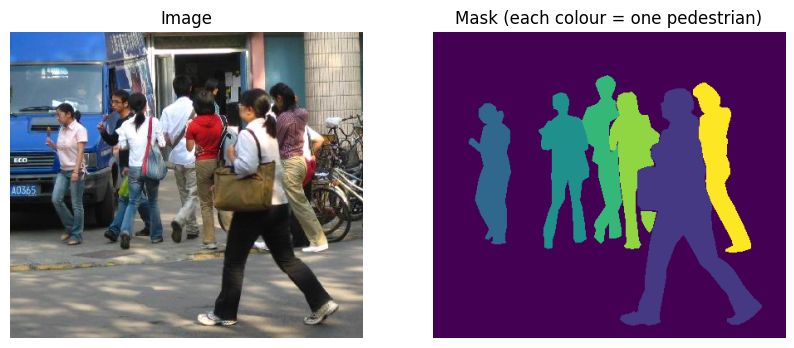

In [4]:
# look at one example: the image, its mask and its annotation file
name = 'FudanPed00025'
img  = Image.open(f'{RAW_DIR}/PNGImages/{name}.png')
mask = np.array(Image.open(f'{RAW_DIR}/PedMasks/{name}_mask.png'))

print('Image size (width, height):', img.size)
print('Mask values (0 = background, 1,2,3.. = each pedestrian):', np.unique(mask))
print()
print(open(f'{RAW_DIR}/Annotation/{name}.txt', encoding='latin-1').read())

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img);  ax[0].set_title('Image')
ax[1].imshow(mask); ax[1].set_title('Mask (each colour = one pedestrian)')
ax[0].axis('off'); ax[1].axis('off')
plt.show()

## Step 2: Read the annotation files
Each annotation file has the image size and one line per pedestrian like
`Bounding box for object 1 "PASpersonWalking" (Xmin, Ymin) - (Xmax, Ymax) : (160, 182) - (302, 431)`.
We use a regular expression (`re`) to pull the numbers out.

In [5]:
def read_annotation(path):
    text = open(path, encoding='latin-1').read()

    # image width and height
    size = re.search(r'Image size \(X x Y x C\)\s*:\s*(\d+)\s*x\s*(\d+)', text)
    W = int(size.group(1))
    H = int(size.group(2))

    # all boxes: (xmin, ymin, xmax, ymax)
    found = re.findall(r'Bounding box for object \d+ .*?:\s*\((\d+),\s*(\d+)\)\s*-\s*\((\d+),\s*(\d+)\)', text)
    boxes = []
    for b in found:
        boxes.append((int(b[0]), int(b[1]), int(b[2]), int(b[3])))
    return W, H, boxes

# test on the example file
W, H, boxes = read_annotation(f'{RAW_DIR}/Annotation/{name}.txt')
print('Width, Height:', W, H)
print('Number of pedestrians:', len(boxes))
print('Boxes (xmin, ymin, xmax, ymax):', boxes)

Width, Height: 425 369
Number of pedestrians: 6
Boxes (xmin, ymin, xmax, ymax): [(226, 69, 396, 354), (44, 87, 94, 256), (128, 74, 189, 262), (180, 53, 228, 255), (213, 73, 273, 262), (314, 62, 383, 266)]


In [6]:
# read ALL annotation files into a dictionary: image name -> (W, H, boxes)
all_ann = {}
for a in annots:
    stem = a[:-4]                      # remove '.txt'
    all_ann[stem] = read_annotation(f'{RAW_DIR}/Annotation/{a}')

total_boxes = sum(len(v[2]) for v in all_ann.values())
print('Annotation files read      :', len(all_ann))
print('Total pedestrians (boxes)  :', total_boxes)
print('Fudan pedestrians          :', sum(len(v[2]) for k, v in all_ann.items() if k.startswith('Fudan')))
print('Penn  pedestrians          :', sum(len(v[2]) for k, v in all_ann.items() if k.startswith('Penn')))
print('Most pedestrians in one image:', max(len(v[2]) for v in all_ann.values()))

Annotation files read      : 170
Total pedestrians (boxes)  : 423
Fudan pedestrians          : 160
Penn  pedestrians          : 263
Most pedestrians in one image: 8


## Step 3: Convert the boxes to YOLO format
YOLO wants one line per box: `class x_center y_center width height` and all numbers divided by the image size (so between 0 and 1).

**Important detail:** the PASCAL boxes start counting pixels at **1** and include the last pixel. So the left edge is `xmin - 1` and the right edge is `xmax`.
```
x_center = (left + right) / 2 / W        width  = (right - left) / W
y_center = (top + bottom) / 2 / H        height = (bottom - top) / H
```

In [7]:
def to_yolo(xmin, ymin, xmax, ymax, W, H):
    left   = xmin - 1      # PASCAL counts from 1, so subtract 1
    top    = ymin - 1
    right  = xmax
    bottom = ymax
    xc = (left + right) / 2 / W
    yc = (top + bottom) / 2 / H
    w  = (right - left) / W
    h  = (bottom - top) / H
    return xc, yc, w, h

# small test by hand: image 100 x 200, box (11, 21) - (60, 120)
# left=10, right=60 -> xc = 35/100 = 0.35, w = 50/100 = 0.5
# top=20, bottom=120 -> yc = 70/200 = 0.35, h = 100/200 = 0.5
result = to_yolo(11, 21, 60, 120, 100, 200)
print('our function gives :', result)
print('hand calculation   : (0.35, 0.35, 0.5, 0.5)')
assert np.allclose(result, (0.35, 0.35, 0.5, 0.5))
print('Test passed')

our function gives : (0.35, 0.35, 0.5, 0.5)
hand calculation   : (0.35, 0.35, 0.5, 0.5)
Test passed


## Step 4: Cross-check the boxes with the masks
The mask gives each pedestrian a different number, so we can also make a box from the mask (smallest rectangle around the pixels).
If the annotation box and the mask box overlap a lot (IoU close to 1), then our boxes are correct.

In [8]:
def mask_boxes(mask_path):
    m = np.array(Image.open(mask_path))
    result = []
    for i in np.unique(m):
        if i == 0:                       # 0 is background
            continue
        ys, xs = np.where(m == i)
        # +1 on the right/bottom because pixel numbers start at 0
        result.append((int(xs.min()), int(ys.min()), int(xs.max()) + 1, int(ys.max()) + 1))
    return result

def get_iou(a, b):
    # a and b are (left, top, right, bottom)
    inter_w = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    inter_h = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = inter_w * inter_h
    area_a = (a[2] - a[0]) * (a[3] - a[1])
    area_b = (b[2] - b[0]) * (b[3] - b[1])
    return inter / (area_a + area_b - inter)

all_ious = []
count_mismatch = []
total_mask_instances = 0
warnings_list = []

for f in images:
    stem = f[:-4]
    W, H, boxes = all_ann[stem]
    mb = mask_boxes(f'{RAW_DIR}/PedMasks/{stem}_mask.png')
    total_mask_instances += len(mb)
    if len(mb) != len(boxes):
        count_mismatch.append(stem)
        warnings_list.append(f'{f}: {len(boxes)} annotation boxes but {len(mb)} mask instances')
    for k, (xmin, ymin, xmax, ymax) in enumerate(boxes):
        a = (xmin - 1, ymin - 1, xmax, ymax)
        best = 0
        for m in mb:
            best = max(best, get_iou(a, m))
        all_ious.append(best)
        if best < 0.85:
            warnings_list.append(f'{f}: object {k+1} annotation-vs-mask IoU {best:.2f}')

all_ious = np.array(all_ious)
print('Pedestrians from annotation files:', total_boxes)
print('Pedestrians from mask images     :', total_mask_instances)
print('Images where the two counts differ:', len(count_mismatch))
print('Average IoU (annotation vs mask) :', round(all_ious.mean(), 3))
print('Lowest IoU                       :', round(all_ious.min(), 3))
print('Boxes with IoU below 0.85        :', int((all_ious < 0.85).sum()), 'of', len(all_ious))

Pedestrians from annotation files: 423
Pedestrians from mask images     : 423
Images where the two counts differ: 0
Average IoU (annotation vs mask) : 0.999
Lowest IoU                       : 0.935
Boxes with IoU below 0.85        : 0 of 423


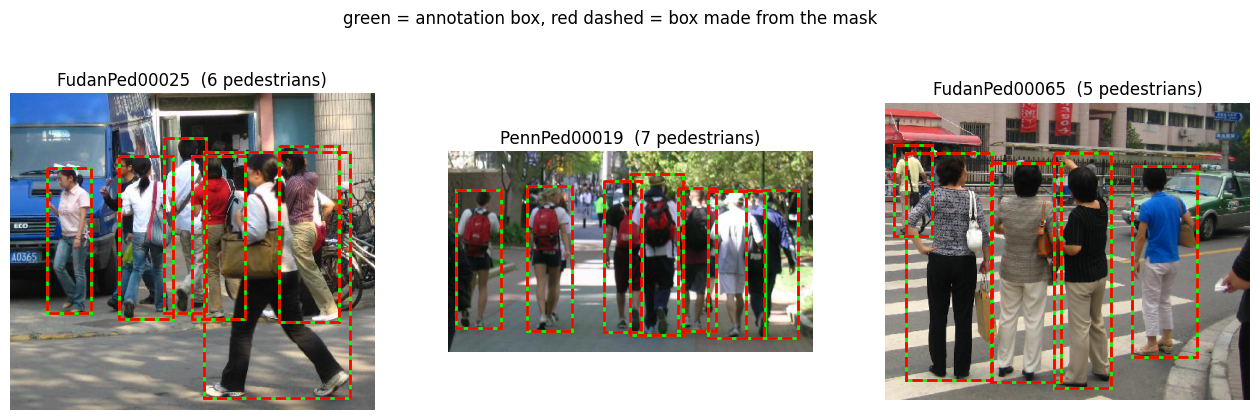

In [9]:
# draw annotation boxes (green) and mask boxes (red dashed) on 3 images
show = ['FudanPed00025', 'PennPed00019', 'FudanPed00065']
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, stem in zip(axes, show):
    ax.imshow(Image.open(f'{RAW_DIR}/PNGImages/{stem}.png'))
    W, H, boxes = all_ann[stem]
    for (xmin, ymin, xmax, ymax) in boxes:
        ax.add_patch(patches.Rectangle((xmin - 1, ymin - 1), xmax - xmin + 1, ymax - ymin + 1,
                                       linewidth=2, edgecolor='lime', facecolor='none'))
    for (l, t, r, b) in mask_boxes(f'{RAW_DIR}/PedMasks/{stem}_mask.png'):
        ax.add_patch(patches.Rectangle((l, t), r - l, b - t, linewidth=2, edgecolor='red',
                                       facecolor='none', linestyle='--'))
    ax.set_title(f'{stem}  ({len(boxes)} pedestrians)')
    ax.axis('off')
plt.suptitle('green = annotation box, red dashed = box made from the mask')
plt.savefig(OUT_DIR + '/figures/annotation_vs_mask.png', bbox_inches='tight')
plt.show()

## Step 5: Split into train / val / test
* Split is **by image** (70% / 15% / 15%), so no image is in two splits.
* We shuffle the sorted image names with `np.random.RandomState(42)` and cut: 170 images -> **119 train, 25 val, 26 test**.
* The test split is only used at the very end (never for tuning).

The team already has a `split_manifest.csv` in the GitHub repo. We clone the repo and check that our split is **exactly the same**.

In [10]:
names = sorted(images)                                   # 170 file names, sorted
order = np.random.RandomState(42).permutation(len(names))

n_train = round(0.70 * len(names))                       # 119  (round, because 0.7*170 is 118.99999 in Python)
n_val   = int(0.15 * len(names))                         # 25   (the remaining 26 images are the test set)
split_of = {}
for rank, idx in enumerate(order):
    if rank < n_train:
        split_of[names[idx]] = 'train'
    elif rank < n_train + n_val:
        split_of[names[idx]] = 'val'
    else:
        split_of[names[idx]] = 'test'

counts = pd.Series(split_of).value_counts()
print('Images per split:')
print(counts[['train', 'val', 'test']])

Images per split:
train    119
val       25
test      26
Name: count, dtype: int64


In [11]:
# compare with the team's manifest from GitHub
!rm -rf /content/repo
!git clone -q https://github.com/ayeshaalamexe/cs320-yolov1.git /content/repo

team_path = '/content/repo/PennFudanYOLO/split_manifest.csv'
if os.path.exists(team_path):
    team = pd.read_csv(team_path)
    same = 0
    for f, s in zip(team.filename, team.split):
        if split_of.get(f) == s:
            same += 1
    print('Images with the same split as the team manifest:', same, 'of', len(team))
else:
    print('Team manifest not found - skipping the comparison')

Images with the same split as the team manifest: 170 of 170


## Step 6: Create the YOLO dataset folders
```
PennFudanYOLO/
  images/train  images/val  images/test      (the PNG images, original size)
  labels/train  labels/val  labels/test      (one .txt per image, one line per pedestrian)
  data.yaml
```
Images keep their original size. The training code resizes them (labels are 0-1 so they stay correct).

In [12]:
if os.path.exists(DATA_DIR):
    shutil.rmtree(DATA_DIR)                  # start clean
for s in ['train', 'val', 'test']:
    os.makedirs(f'{DATA_DIR}/images/{s}')
    os.makedirs(f'{DATA_DIR}/labels/{s}')

issues = {'missing_annotation': [], 'missing_mask': [], 'size_mismatch': [], 'invalid_boxes': []}
manifest_rows = []

for f in images:
    stem = f[:-4]
    split = split_of[f]
    img = Image.open(f'{RAW_DIR}/PNGImages/{f}')
    W, H = img.size

    if stem not in all_ann:
        issues['missing_annotation'].append(f)
        continue
    if not os.path.exists(f'{RAW_DIR}/PedMasks/{stem}_mask.png'):
        issues['missing_mask'].append(f)
    if (all_ann[stem][0], all_ann[stem][1]) != (W, H):
        issues['size_mismatch'].append(f)
        continue

    # convert every box and make the label lines
    lines = []
    for (xmin, ymin, xmax, ymax) in all_ann[stem][2]:
        if xmin < 1 or ymin < 1 or xmin >= xmax or ymin >= ymax or xmax > W or ymax > H:
            issues['invalid_boxes'].append(f)
            continue
        xc, yc, w, h = to_yolo(xmin, ymin, xmax, ymax, W, H)
        lines.append(f'0 {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}')       # class 0 = pedestrian

    shutil.copy(f'{RAW_DIR}/PNGImages/{f}', f'{DATA_DIR}/images/{split}/{f}')
    with open(f'{DATA_DIR}/labels/{split}/{stem}.txt', 'w') as out:
        out.write('\n'.join(lines) + '\n')

    source = 'Fudan' if f.startswith('Fudan') else 'Penn'
    manifest_rows.append([f, split, source, W, H, len(lines), 'annotation'])

# the manifest = a table that says which image is in which split
manifest = pd.DataFrame(manifest_rows, columns=['filename', 'split', 'source_set', 'width', 'height',
                                                'n_pedestrians', 'label_source'])
split_order = {'test': 0, 'train': 1, 'val': 2}
manifest['o'] = manifest.split.map(split_order)
manifest = manifest.sort_values(['o', 'filename']).drop(columns='o').reset_index(drop=True)
manifest.to_csv(OUT_DIR + '/split_manifest.csv', index=False)

# conversion log
with open(OUT_DIR + '/conversion_log.txt', 'w') as log:
    log.write('ISSUES\n' + json.dumps(issues, indent=2) + '\n\nWARNINGS\n')
    for w in warnings_list:
        log.write(w + '\n')

print('Images converted:', len(manifest))
print('Issues found    :', {k: len(v) for k, v in issues.items()})
print()
manifest.head(8)

Images converted: 170
Issues found    : {'missing_annotation': 0, 'missing_mask': 0, 'size_mismatch': 0, 'invalid_boxes': 0}



,filename,split,source_set,width,height,n_pedestrians,label_source
0,FudanPed00002.png,test,Fudan,455,414,1,annotation
1,FudanPed00015.png,test,Fudan,336,349,1,annotation
2,FudanPed00021.png,test,Fudan,490,378,3,annotation
3,FudanPed00022.png,test,Fudan,536,465,2,annotation
4,FudanPed00038.png,test,Fudan,422,346,1,annotation
5,FudanPed00049.png,test,Fudan,447,512,3,annotation
6,FudanPed00053.png,test,Fudan,541,580,2,annotation
7,FudanPed00058.png,test,Fudan,522,479,8,annotation


In [13]:
# data.yaml tells YOLO where the data is
yaml_text = f'''# Penn-Fudan, single class
path: {DATA_DIR}
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: pedestrian
'''
open(DATA_DIR + '/data.yaml', 'w').write(yaml_text)
open(OUT_DIR + '/data.yaml', 'w').write(yaml_text)
print(yaml_text)

print('Example label file (FudanPed00025.txt):')
print(open(DATA_DIR + '/labels/train/FudanPed00025.txt').read() if os.path.exists(DATA_DIR + '/labels/train/FudanPed00025.txt') else '(this image is not in train)')

# Penn-Fudan, single class
path: /content/PennFudanYOLO
train: images/train
val: images/val
test: images/test
nc: 1
names:
  0: pedestrian

Example label file (FudanPed00025.txt):
0 0.730588 0.571816 0.402353 0.775068
0 0.161176 0.463415 0.120000 0.460705
0 0.371765 0.453930 0.145882 0.512195
0 0.478824 0.415989 0.115294 0.550136
0 0.570588 0.452575 0.143529 0.514905
0 0.818824 0.443089 0.164706 0.555556



## Step 7: Quality checks
We re-read the files we saved and check them. Every line must say **PASS**.

In [14]:
# read all saved labels once
labels = {}                         # (split, image stem) -> list of rows, each row = list of strings
for s in ['train', 'val', 'test']:
    for lf in sorted(os.listdir(f'{DATA_DIR}/labels/{s}')):
        rows = []
        for line in open(f'{DATA_DIR}/labels/{s}/{lf}').read().splitlines():
            if line.strip() != '':
                rows.append(line.split())
        labels[(s, lf[:-4])] = rows

report = []
def check(number, text, problems):
    if len(problems) == 0:
        line = f'PASS  {number}. {text}  -> all good'
    else:
        line = f'FAIL  {number}. {text}  -> {len(problems)} problem(s), e.g. {problems[:3]}'
    print(line)
    report.append(line)

imgs_in = {}
for s in ['train', 'val', 'test']:
    imgs_in[s] = sorted(os.listdir(f'{DATA_DIR}/images/{s}'))

# 1. every image has a label file
p = []
for s in imgs_in:
    for f in imgs_in[s]:
        if (s, f[:-4]) not in labels:
            p.append(f)
check(1, 'Every image has a label file', p)

# 2. every label row has exactly 5 numbers
p = []
for key, rows in labels.items():
    for r in rows:
        if len(r) != 5:
            p.append(key)
check(2, 'Label rows are valid YOLO (5 fields)', p)

# 3. class id must be 0 (only one class)
p = []
for key, rows in labels.items():
    for r in rows:
        if r[0] != '0':
            p.append(key)
check(3, 'Class IDs valid (only 0)', p)

# 4. all values between 0 and 1, and the whole box is inside the image
p = []
for key, rows in labels.items():
    for r in rows:
        xc, yc, w, h = [float(v) for v in r[1:]]
        if xc - w/2 < -1e-5 or yc - h/2 < -1e-5 or xc + w/2 > 1 + 1e-5 or yc + h/2 > 1 + 1e-5:
            p.append(key)
check(4, 'Normalised values within 0-1 (boxes inside image)', p)

# 5. width and height must be positive
p = []
for key, rows in labels.items():
    for r in rows:
        if float(r[3]) <= 0 or float(r[4]) <= 0:
            p.append(key)
check(5, 'Positive box width/height', p)

# 6. no image in more than one split
all_names = imgs_in['train'] + imgs_in['val'] + imgs_in['test']
p = [n for n in set(all_names) if all_names.count(n) > 1]
check(6, 'No image in more than one split', p)

# 7. number of images = number of labels in each split
p = []
for s in imgs_in:
    n_labels = len([k for k in labels if k[0] == s])
    if len(imgs_in[s]) != n_labels:
        p.append(f'{s}: {len(imgs_in[s])} images, {n_labels} labels')
check(7, 'Image count == label count per split', p)

# 8. each split has the right number of images and pedestrians (compare with the manifest)
p = []
for s in imgs_in:
    want_imgs = int((manifest.split == s).sum())
    want_inst = int(manifest[manifest.split == s].n_pedestrians.sum())
    got_inst = sum(len(rows) for k, rows in labels.items() if k[0] == s)
    if len(imgs_in[s]) != want_imgs or got_inst != want_inst:
        p.append(f'{s}: {len(imgs_in[s])}/{want_imgs} images, {got_inst}/{want_inst} pedestrians')
check(8, 'Each split has the expected files / instance total', p)

# 9. data.yaml points to real folders
import yaml
cfg = yaml.safe_load(open(DATA_DIR + '/data.yaml'))
p = []
for k in ['train', 'val', 'test']:
    if not os.path.isdir(os.path.join(cfg['path'], cfg[k])):
        p.append(k)
if cfg['nc'] != 1:
    p.append('nc is not 1')
check(9, 'data.yaml points to valid directories', p)

# 10. saved labels = boxes converted again from the original annotation files
p = []
for (s, stem), rows in labels.items():
    W, H, boxes = all_ann[stem]
    if len(rows) != len(boxes):
        p.append(stem)
        continue
    for r, b in zip(rows, boxes):
        want = to_yolo(b[0], b[1], b[2], b[3], W, H)
        got = [float(v) for v in r[1:]]
        if max(abs(want[i] - got[i]) for i in range(4)) > 1e-5:
            p.append(stem)
check(10, 'Saved labels match original annotation boxes (all files)', p)

# 11. image sizes on disk = sizes in the manifest
p = []
for r in manifest.itertuples():
    w, h = Image.open(f'{DATA_DIR}/images/{r.split}/{r.filename}').size
    if (w, h) != (r.width, r.height):
        p.append(r.filename)
check(11, 'Image sizes match the manifest', p)

# 12. no two images are exactly the same file (would leak between splits)
seen = {}
p = []
for s in imgs_in:
    for f in imgs_in[s]:
        digest = hashlib.md5(open(f'{DATA_DIR}/images/{s}/{f}', 'rb').read()).hexdigest()
        if digest in seen:
            p.append(f'{f} = {seen[digest]}')
        seen[digest] = f
check(12, 'No identical images across splits', p)

open(OUT_DIR + '/quality_report.txt', 'w').write('\n'.join(report) + '\n')
n_fail = sum(1 for line in report if line.startswith('FAIL'))
print()
print('ALL CHECKS PASSED' if n_fail == 0 else f'{n_fail} CHECK(S) FAILED - fix before training!')

PASS  1. Every image has a label file  -> all good
PASS  2. Label rows are valid YOLO (5 fields)  -> all good
PASS  3. Class IDs valid (only 0)  -> all good
PASS  4. Normalised values within 0-1 (boxes inside image)  -> all good
PASS  5. Positive box width/height  -> all good
PASS  6. No image in more than one split  -> all good
PASS  7. Image count == label count per split  -> all good
PASS  8. Each split has the expected files / instance total  -> all good
PASS  9. data.yaml points to valid directories  -> all good
PASS  10. Saved labels match original annotation boxes (all files)  -> all good
PASS  11. Image sizes match the manifest  -> all good
PASS  12. No identical images across splits  -> all good

ALL CHECKS PASSED


## Step 8: Dataset statistics

In [15]:
# one row per box, read from the SAVED label files
box_rows = []
for (s, stem), rows in labels.items():
    r0 = manifest[manifest.filename == stem + '.png'].iloc[0]
    for r in rows:
        xc, yc, w, h = [float(v) for v in r[1:]]
        box_rows.append([stem + '.png', s, r0.source_set, xc, yc, w, h, w * r0.width, h * r0.height])
boxes_df = pd.DataFrame(box_rows, columns=['filename', 'split', 'source', 'xc', 'yc', 'w', 'h', 'w_px', 'h_px'])

# main table (images and pedestrians per split)
stats = [['Total', len(manifest), len(boxes_df)]]
for s in ['train', 'val', 'test']:
    stats.append([s.capitalize(), int((manifest.split == s).sum()), int((boxes_df.split == s).sum())])
stats.append(['Invalid / missing files or boxes', sum(len(v) for v in issues.values()), '-'])
stats_df = pd.DataFrame(stats, columns=['Metric', 'Images', 'Pedestrian instances'])
stats_df.to_csv(OUT_DIR + '/dataset_stats.csv', index=False)
print(stats_df.to_string(index=False))

# extra table: more details for each split
extra = []
for s in ['train', 'val', 'test']:
    b = boxes_df[boxes_df.split == s]
    m = manifest[manifest.split == s]
    extra.append([s, len(m), len(b), round(len(b) / len(m), 2), int(m.n_pedestrians.max()),
                  round(b.h_px.median()), round(b.w_px.median()),
                  round((b.h / b.w).median(), 2), int((b.h_px < 100).sum())])
extra_df = pd.DataFrame(extra, columns=['split', 'images', 'pedestrians', 'avg per image', 'max per image',
                                        'median height px', 'median width px', 'median h/w', 'boxes shorter than 100px'])
extra_df.to_csv(OUT_DIR + '/dataset_stats_extra.csv', index=False)
print()
print(extra_df.to_string(index=False))

                          Metric  Images Pedestrian instances
                           Total     170                  423
                           Train     119                  295
                             Val      25                   55
                            Test      26                   73
Invalid / missing files or boxes       0                    -

split  images  pedestrians  avg per image  max per image  median height px  median width px  median h/w  boxes shorter than 100px
train     119          295           2.48              7               284              100        3.41                         8
  val      25           55           2.20              6               290              104        3.52                         1
 test      26           73           2.81              8               288               98        3.65                         8


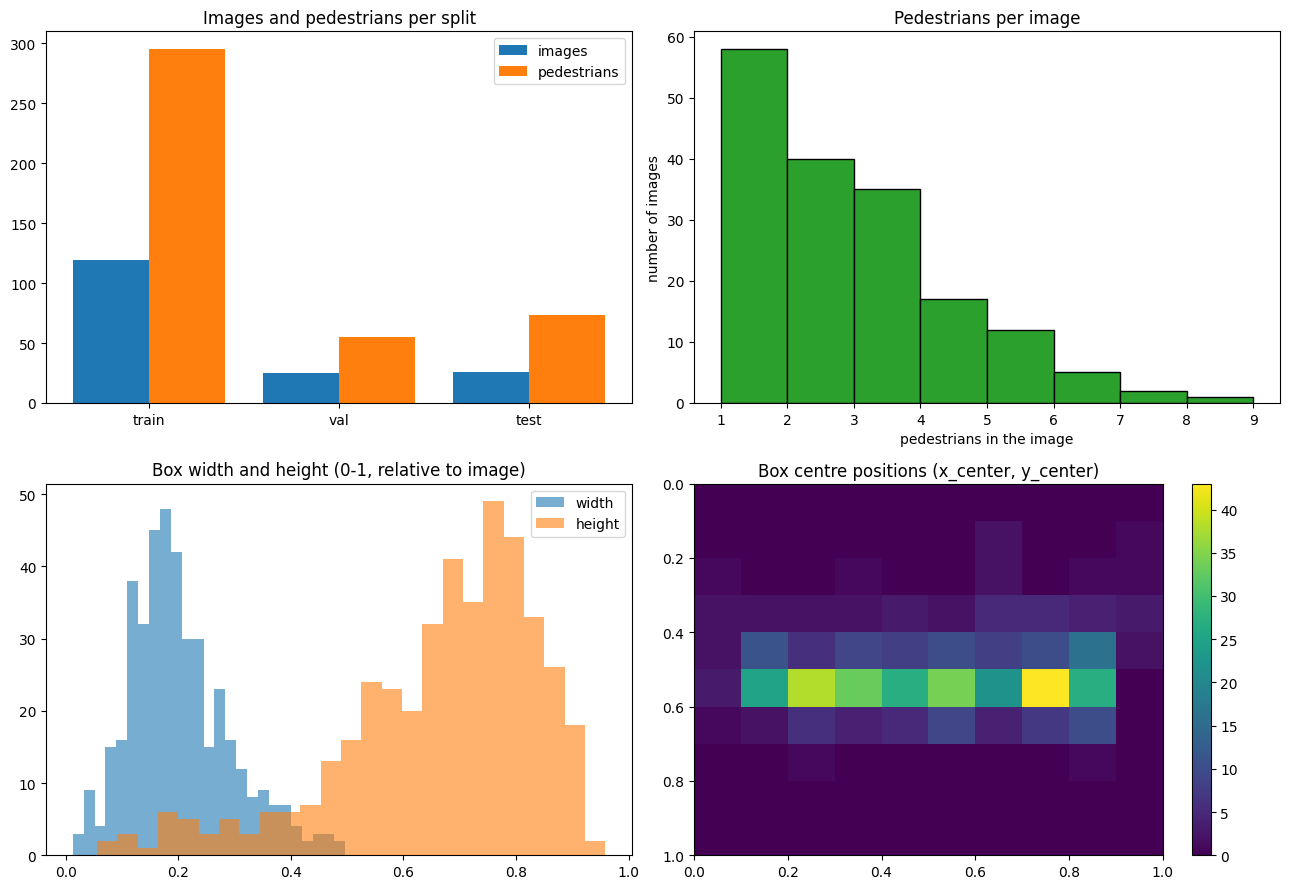

In [16]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

# 1. images and pedestrians per split
x = np.arange(3)
ax[0, 0].bar(x - 0.2, [stats[1][1], stats[2][1], stats[3][1]], 0.4, label='images')
ax[0, 0].bar(x + 0.2, [stats[1][2], stats[2][2], stats[3][2]], 0.4, label='pedestrians')
ax[0, 0].set_xticks(x); ax[0, 0].set_xticklabels(['train', 'val', 'test'])
ax[0, 0].set_title('Images and pedestrians per split'); ax[0, 0].legend()

# 2. how many pedestrians in each image
ax[0, 1].hist(manifest.n_pedestrians, bins=range(1, manifest.n_pedestrians.max() + 2), color='tab:green', edgecolor='black')
ax[0, 1].set_title('Pedestrians per image'); ax[0, 1].set_xlabel('pedestrians in the image'); ax[0, 1].set_ylabel('number of images')

# 3. box size (relative to the image)
ax[1, 0].hist(boxes_df.w, bins=25, alpha=0.6, label='width')
ax[1, 0].hist(boxes_df.h, bins=25, alpha=0.6, label='height')
ax[1, 0].set_title('Box width and height (0-1, relative to image)'); ax[1, 0].legend()

# 4. where the box centres are
hb = ax[1, 1].hist2d(boxes_df.xc, boxes_df.yc, bins=10, range=[[0, 1], [0, 1]], cmap='viridis')
ax[1, 1].invert_yaxis()
ax[1, 1].set_title('Box centre positions (x_center, y_center)')
plt.colorbar(hb[3], ax=ax[1, 1])

plt.tight_layout()
plt.savefig(OUT_DIR + '/figures/dataset_stats.png', bbox_inches='tight')
plt.show()

## Step 9: Look at the saved labels
Boxes drawn from the **saved label files** (not from the annotation files), so if these look right the whole pipeline is right.

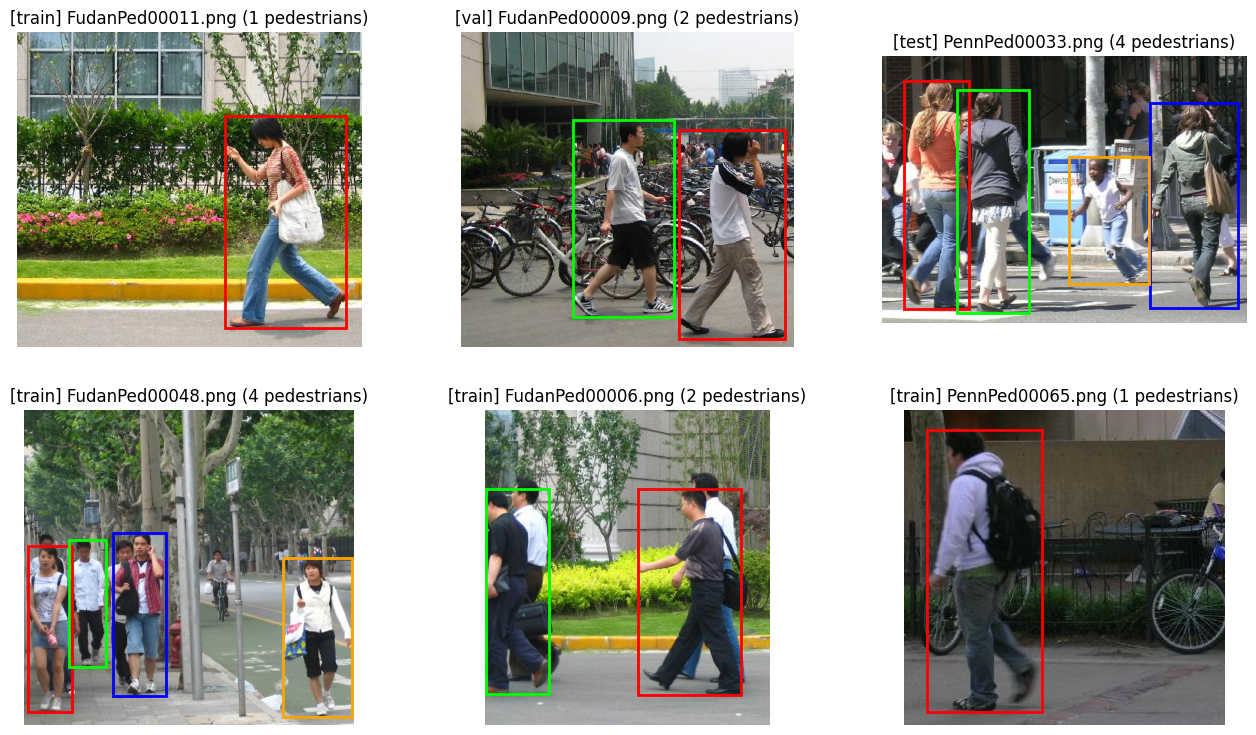

In [17]:
random.seed(1)
picks = random.sample(list(manifest.itertuples()), 6)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
colors = ['red', 'lime', 'blue', 'orange', 'purple', 'cyan', 'yellow', 'magenta']
for ax, r in zip(axes.flat, picks):
    stem = r.filename[:-4]
    ax.imshow(Image.open(f'{DATA_DIR}/images/{r.split}/{r.filename}'))
    rows = labels[(r.split, stem)]
    for k, row in enumerate(rows):
        xc, yc, w, h = [float(v) for v in row[1:]]
        left = (xc - w / 2) * r.width            # back from 0-1 to pixels
        top  = (yc - h / 2) * r.height
        ax.add_patch(patches.Rectangle((left, top), w * r.width, h * r.height, linewidth=2,
                                       edgecolor=colors[k % len(colors)], facecolor='none'))
    ax.set_title(f'[{r.split}] {r.filename} ({len(rows)} pedestrians)')
    ax.axis('off')
plt.savefig(OUT_DIR + '/figures/label_check_samples.png', bbox_inches='tight')
plt.show()

## Step 10: Ablation - with vs without data augmentation (RQ2)
**Question:** does data augmentation help when we train on the small Penn-Fudan dataset?

**How we test it fairly:** we use the modern Ultralytics YOLO (`yolo11n`, pretrained). The ONLY thing that changes is the augmentation settings. Everything else is the same:

| same for both | value |
|---|---|
| model | yolo11n.pt |
| epochs / image size / batch | 50 / 640 / 16 |
| data split | 119 train / 25 val / 26 test |
| seeds | 0, 1, 2 (3 runs each, because the dataset is tiny and one run can be lucky) |

* `no_aug`: all augmentations set to 0 (no flip, no colour change, no scale/shift, no mosaic).
* `default_aug`: the default Ultralytics augmentation (flip, colour change, scale, shift, mosaic).

We pick the best epoch using the **val** split and measure on the **test** split once at the end.
(These are the same settings as the team's earlier results in `results/`, so the numbers can be compared.)

In [18]:
!pip install -q ultralytics
import torch
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU name     :', torch.cuda.get_device_name(0))

GPU available: True
GPU name     : Tesla T4


In [19]:
from ultralytics import YOLO

MODEL  = 'yolo11n.pt'
EPOCHS = 50
IMG    = 640
BATCH  = 16
SEEDS  = [0, 1, 2]

# augmentation settings: only these change between the two experiments
no_aug = dict(hsv_h=0, hsv_s=0, hsv_v=0,          # colour change
              degrees=0, translate=0, scale=0,    # rotate, shift, zoom
              shear=0, perspective=0,
              flipud=0, fliplr=0,                 # flips
              mosaic=0, mixup=0, close_mosaic=0)  # mosaic = 4 images glued together

default_aug = dict(hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
                   degrees=0, translate=0.1, scale=0.5,
                   shear=0, perspective=0,
                   flipud=0, fliplr=0.5,
                   mosaic=1.0, mixup=0, close_mosaic=10)   # mosaic is switched off for the last 10 epochs

settings = {'no_aug': no_aug, 'default_aug': default_aug}
print(pd.DataFrame(settings).to_string())

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
              no_aug  default_aug
hsv_h              0        0.015
hsv_s              0        0.700
hsv_v              0        0.400
degrees            0        0.000
translate          0        0.100
scale              0        0.500
shear              0        0.000
perspective        0        0.000
flipud             0        0.000
fliplr             0        0.500
mosaic             0        1.000
mixup              0        0.000
close_mosaic       0       10.000


In [20]:
def train_and_test(variant, seed):
    # one training run + evaluation on val and test
    extra = dict(settings[variant])
    if variant == 'no_aug':
        # Ultralytics also has hidden light augmentations (blur, grayscale) from the albumentations
        # library. An empty list switches them off, so 'no_aug' really means no augmentation.
        extra['augmentations'] = []

    model = YOLO(MODEL)
    model.train(data=DATA_DIR + '/data.yaml', epochs=EPOCHS, imgsz=IMG, batch=BATCH, seed=seed,
                project='/content/runs', name=f'{variant}_seed{seed}', exist_ok=True,
                plots=False, verbose=False, **extra)

    best = YOLO(model.trainer.best)                   # best weights (chosen on val)
    row = {'variant': variant, 'seed': seed}
    for split in ['val', 'test']:
        m = best.val(data=DATA_DIR + '/data.yaml', split=split, imgsz=IMG, conf=0.001, iou=0.6,
                     plots=False, verbose=False)
        row[split + '_map50']      = float(m.box.map50)    # mAP at IoU 0.5
        row[split + '_map50_95']   = float(m.box.map)      # mAP at IoU 0.5 to 0.95
        row[split + '_precision']  = float(m.box.mp)
        row[split + '_recall']     = float(m.box.mr)
    row['inference_ms'] = float(m.speed['inference'])
    return row
print('function ready')

function ready


In [21]:
# run all 6 experiments (2 variants x 3 seeds). The csv is saved after every run.
ABL_DIR = OUT_DIR + '/ablation'
os.makedirs(ABL_DIR, exist_ok=True)
csv_path = ABL_DIR + '/aug_ablation_runs.csv'

results = []
if os.path.exists(csv_path):                          # if the session restarted, continue from the saved runs
    results = pd.read_csv(csv_path).to_dict('records')
done = [(r['variant'], r['seed']) for r in results]

for variant in settings:
    for seed in SEEDS:
        if (variant, seed) in done:
            print('skip (already done):', variant, seed)
            continue
        print('=' * 60)
        print('Training:', variant, '| seed', seed)
        results.append(train_and_test(variant, seed))
        pd.DataFrame(results).to_csv(csv_path, index=False)

runs_df = pd.DataFrame(results)
runs_df

Training: no_aug | seed 0
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, augmentations=[], auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/PennFudanYOLO/data.yaml, degrees=0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0, flipud=0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0, hsv_s=0, hsv_v=0, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=0, multi_scale=0.0, name=no_aug_seed0, nbs=64, nms=None, 

,variant,seed,val_map50,val_map50_95,val_precision,val_recall,test_map50,test_map50_95,test_precision,test_recall,inference_ms
0,no_aug,0,0.913017,0.645314,0.943006,0.902567,0.908019,0.628005,0.879367,0.835616,5.554574
1,no_aug,1,0.949246,0.673176,0.958451,0.890909,0.933316,0.633994,0.913751,0.870814,4.566772
2,no_aug,2,0.963681,0.679562,0.974597,0.872727,0.905790,0.642017,0.944237,0.780822,3.890829
3,default_aug,0,0.977607,0.801241,0.998265,0.890909,0.977748,0.776610,0.956177,0.904110,5.414120
4,default_aug,1,0.964212,0.772050,0.997456,0.909091,0.971111,0.762315,0.942762,0.902533,5.360454
5,default_aug,2,0.989589,0.829814,0.963723,0.966065,0.973755,0.785754,0.965827,0.876712,5.219340


In [22]:
# summary table: mean +- standard deviation over the 3 seeds
cols = ['test_map50', 'test_map50_95', 'test_precision', 'test_recall', 'val_map50', 'val_map50_95']
mean = runs_df.groupby('variant')[cols].mean()
std  = runs_df.groupby('variant')[cols].std()

summary = pd.DataFrame(index=mean.index)
for c in cols:
    summary[c] = [f'{mean.loc[v, c]:.3f} +- {std.loc[v, c]:.3f}' for v in mean.index]
summary.to_csv(ABL_DIR + '/aug_ablation_summary.csv')
print('Mean +- std over', len(SEEDS), 'seeds')
summary

Mean +- std over 3 seeds


,test_map50,test_map50_95,test_precision,test_recall,val_map50,val_map50_95
variant,,,,,,
default_aug,0.974 +- 0.003,0.775 +- 0.012,0.955 +- 0.012,0.894 +- 0.015,0.977 +- 0.013,0.801 +- 0.029
no_aug,0.916 +- 0.015,0.635 +- 0.007,0.912 +- 0.032,0.829 +- 0.045,0.942 +- 0.026,0.666 +- 0.018


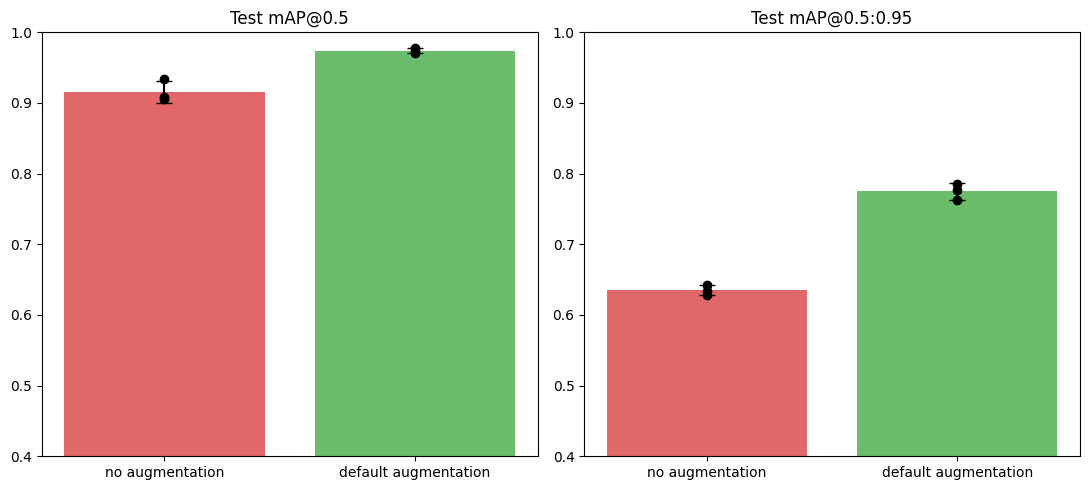

In [23]:
# bar chart: test mAP for both variants (error bar = std, dots = single runs)
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a, metric, title in [(ax[0], 'test_map50', 'Test mAP@0.5'), (ax[1], 'test_map50_95', 'Test mAP@0.5:0.95')]:
    for i, v in enumerate(['no_aug', 'default_aug']):
        vals = runs_df[runs_df.variant == v][metric]
        a.bar(i, vals.mean(), yerr=vals.std(), capsize=6, color=['tab:red', 'tab:green'][i], alpha=0.7)
        a.scatter([i] * len(vals), vals, color='black', zorder=3)
    a.set_xticks([0, 1]); a.set_xticklabels(['no augmentation', 'default augmentation'])
    a.set_title(title); a.set_ylim(0.4, 1.0)
plt.tight_layout()
plt.savefig(ABL_DIR + '/aug_ablation_bars.png', bbox_inches='tight')
plt.show()

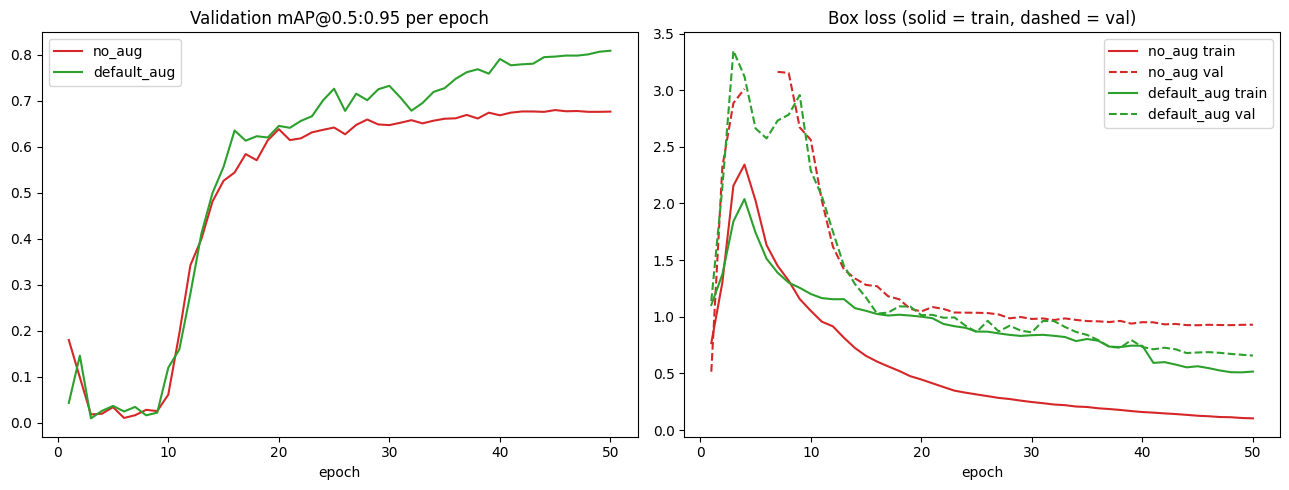

In [24]:
# learning curves: mean over the seeds, read from the results.csv that Ultralytics saved for each run
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for v, color in [('no_aug', 'tab:red'), ('default_aug', 'tab:green')]:
    curves = []
    for seed in SEEDS:
        d = pd.read_csv(f'/content/runs/{v}_seed{seed}/results.csv')
        d.columns = d.columns.str.strip()                 # column names have extra spaces
        curves.append(d)
    ep  = curves[0]['epoch']
    map_ = np.mean([c['metrics/mAP50-95(B)'] for c in curves], axis=0)
    trn  = np.mean([c['train/box_loss'] for c in curves], axis=0)
    val  = np.mean([c['val/box_loss'] for c in curves], axis=0)
    ax[0].plot(ep, map_, color=color, label=v)
    ax[1].plot(ep, trn, color=color, label=v + ' train')
    ax[1].plot(ep, val, color=color, linestyle='--', label=v + ' val')
ax[0].set_title('Validation mAP@0.5:0.95 per epoch'); ax[0].set_xlabel('epoch'); ax[0].legend()
ax[1].set_title('Box loss (solid = train, dashed = val)'); ax[1].set_xlabel('epoch'); ax[1].legend()
plt.tight_layout()
plt.savefig(ABL_DIR + '/aug_ablation_curves.png', bbox_inches='tight')
plt.show()

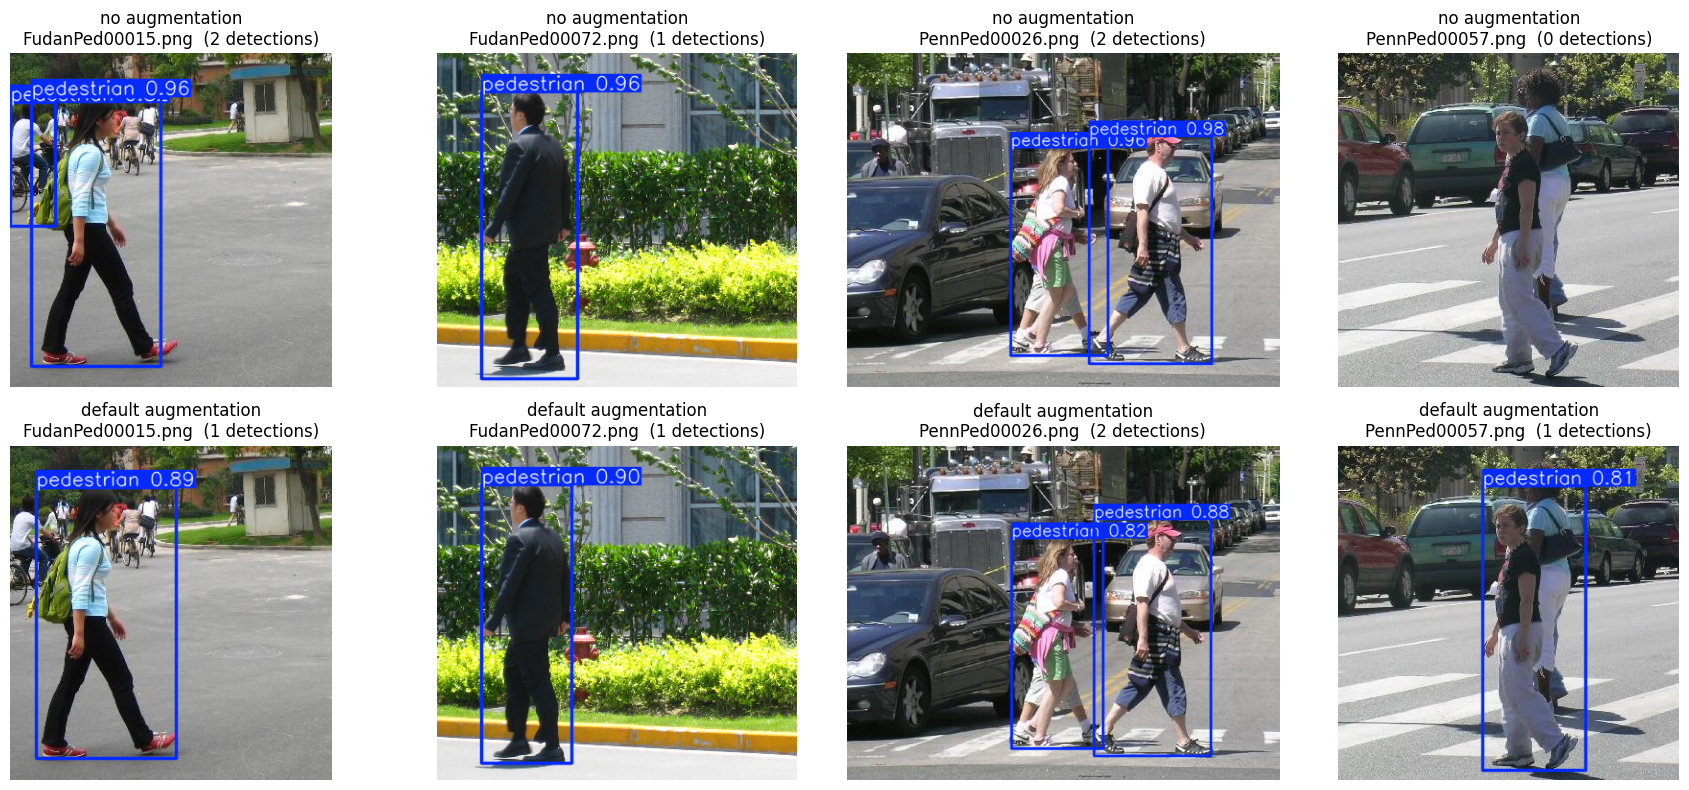

In [25]:
# predictions of the two models on the same 4 test images (seed 0)
m_no  = YOLO('/content/runs/no_aug_seed0/weights/best.pt')
m_aug = YOLO('/content/runs/default_aug_seed0/weights/best.pt')
test_files = sorted(os.listdir(DATA_DIR + '/images/test'))
chosen = [test_files[i] for i in [1, 8, 13, 20]]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for j, f in enumerate(chosen):
    path = f'{DATA_DIR}/images/test/{f}'
    for i, (model, title) in enumerate([(m_no, 'no augmentation'), (m_aug, 'default augmentation')]):
        res = model.predict(path, imgsz=IMG, conf=0.25, verbose=False)[0]
        axes[i, j].imshow(res.plot()[:, :, ::-1])      # plot() gives BGR, we need RGB
        axes[i, j].set_title(f'{title}\n{f}  ({len(res.boxes)} detections)')
        axes[i, j].axis('off')
plt.tight_layout()
plt.savefig(ABL_DIR + '/aug_ablation_predictions.png', bbox_inches='tight')
plt.show()

In [26]:
# conclusion written from the numbers (so it always matches the results)
lines = []
for metric in ['test_map50', 'test_map50_95', 'test_recall']:
    a = runs_df[runs_df.variant == 'no_aug'][metric]
    b = runs_df[runs_df.variant == 'default_aug'][metric]
    diff = b.mean() - a.mean()
    noise = max(a.std(), b.std())
    if abs(diff) > noise:
        verdict = 'bigger than the seed-to-seed noise -> real effect'
    else:
        verdict = 'within the seed-to-seed noise -> not clear'
    lines.append(f'{metric}: no_aug {a.mean():.3f}, default_aug {b.mean():.3f}, difference {diff:+.3f} ({verdict})')

for l in lines:
    print(l)

conclusion = ('# Augmentation ablation (RQ2) - yolo11n, ' + str(EPOCHS) + ' epochs, imgsz ' + str(IMG) +
              ', seeds ' + str(SEEDS) + '\n\n' + '\n'.join('* ' + l for l in lines) +
              '\n\nMean +- std over seeds:\n\n' + summary.to_markdown() +
              '\n\nNote: yolo11n is COCO-pretrained and already knows `person`, and the test set has only 26 images, '
              'so the effect size should be read together with the seed standard deviation.\n')
open(ABL_DIR + '/aug_ablation_report.md', 'w').write(conclusion)

test_map50: no_aug 0.916, default_aug 0.974, difference +0.058 (bigger than the seed-to-seed noise -> real effect)
test_map50_95: no_aug 0.635, default_aug 0.775, difference +0.140 (bigger than the seed-to-seed noise -> real effect)
test_recall: no_aug 0.829, default_aug 0.894, difference +0.065 (bigger than the seed-to-seed noise -> real effect)


1121

## Step 11: Save everything and push to GitHub
We collect the small files (no images, no model weights) in one folder `hassaan_simple/` and push them to a **new branch**,
so nothing in the team's `main` branch can be overwritten. Then open a Pull Request on GitHub.

**Before running the last cell you need a GitHub token:** GitHub -> Settings -> Developer settings -> Personal access tokens -> Tokens (classic)
-> Generate new token -> tick **repo** -> copy it. (You must be a collaborator on the repo.)

In [27]:
# copy the labels into the output folder (they are tiny text files) and make a zip as a backup
shutil.copytree(DATA_DIR + '/labels', OUT_DIR + '/labels', dirs_exist_ok=True)
shutil.make_archive('/content/hassaan_outputs', 'zip', OUT_DIR)

print('Files that will be pushed:')
for folder, _, files_in in sorted(os.walk(OUT_DIR)):
    if folder.endswith('labels') or '/labels/' in folder:
        continue
    for f in sorted(files_in):
        print('  ', os.path.relpath(os.path.join(folder, f), OUT_DIR))
print('   labels/  (', len(labels), 'label files )')

try:
    from google.colab import files
    files.download('/content/hassaan_outputs.zip')     # also download a backup copy
except Exception:
    print('(not running in Colab, skipped the download)')

Files that will be pushed:
   conversion_log.txt
   data.yaml
   dataset_stats.csv
   dataset_stats_extra.csv
   quality_report.txt
   split_manifest.csv
   ablation/aug_ablation_bars.png
   ablation/aug_ablation_curves.png
   ablation/aug_ablation_predictions.png
   ablation/aug_ablation_report.md
   ablation/aug_ablation_runs.csv
   ablation/aug_ablation_summary.csv
   figures/annotation_vs_mask.png
   figures/dataset_stats.png
   figures/label_check_samples.png
   labels/  ( 170 label files )


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
# ---------- PUSH TO GITHUB ----------
import subprocess
from getpass import getpass

REPO       = 'ayeshaalamexe/cs320-yolov1'
BRANCH     = 'hassaan/data-notebook'        # new branch (does not touch main)
FOLDER     = 'hassaan_work'                 # folder inside the repo
GIT_NAME   = 'hassaanadil27'
GIT_EMAIL  = 'thorknight1999@gmail.com'     # <-- change this

if GIT_EMAIL.startswith('PUT_'):
    raise SystemExit('Please write your GitHub email in GIT_EMAIL above and run this cell again.')

TOKEN  = getpass('Paste your GitHub token (hidden): ')
REMOTE = f'https://{TOKEN}@github.com/{REPO}.git'
PUSH_DIR = '/content/repo_push'

def run(cmd, folder=None):
    out = subprocess.run(cmd, shell=True, cwd=folder, capture_output=True, text=True)
    text = (out.stdout + out.stderr).replace(TOKEN, '***')     # never print the token
    if out.returncode != 0:
        raise RuntimeError('Command failed: ' + cmd.replace(TOKEN, '***') + '\n' + text)
    return text

run(f'rm -rf {PUSH_DIR}')
run(f'git clone -q {REMOTE} {PUSH_DIR}')
run(f'git config user.name "{GIT_NAME}"', PUSH_DIR)
run(f'git config user.email "{GIT_EMAIL}"', PUSH_DIR)
run(f'git checkout -b {BRANCH}', PUSH_DIR)

# copy our files into the repo folder
target = f'{PUSH_DIR}/{FOLDER}'
os.makedirs(target, exist_ok=True)
run(f'cp -r {OUT_DIR}/. {target}/')
if os.path.exists('/content/Hassaan_Simple_All_In_One.ipynb'):     # optional: the notebook itself, if uploaded
    run(f'cp /content/Hassaan_Simple_All_In_One.ipynb {target}/')

run('git add -A', PUSH_DIR)
print(run('git status --short', PUSH_DIR)[:1500])
run('git commit -q -m "Hassaan: simple all-in-one notebook (Penn-Fudan to YOLO, checks, stats, augmentation ablation)"', PUSH_DIR)
print(run(f'git push -u origin {BRANCH}', PUSH_DIR))
run(f'git remote set-url origin https://github.com/{REPO}.git', PUSH_DIR)   # remove the token from the repo config

print('DONE. Open this link to create the Pull Request:')
print(f'https://github.com/{REPO}/pull/new/{BRANCH}')

Paste your GitHub token (hidden): ··········
A  hassaan_work/ablation/aug_ablation_bars.png
A  hassaan_work/ablation/aug_ablation_curves.png
A  hassaan_work/ablation/aug_ablation_predictions.png
A  hassaan_work/ablation/aug_ablation_report.md
A  hassaan_work/ablation/aug_ablation_runs.csv
A  hassaan_work/ablation/aug_ablation_summary.csv
A  hassaan_work/conversion_log.txt
A  hassaan_work/data.yaml
A  hassaan_work/dataset_stats.csv
A  hassaan_work/dataset_stats_extra.csv
A  hassaan_work/figures/annotation_vs_mask.png
A  hassaan_work/figures/dataset_stats.png
A  hassaan_work/figures/label_check_samples.png
A  hassaan_work/labels/test.cache
A  hassaan_work/labels/test/FudanPed00002.txt
A  hassaan_work/labels/test/FudanPed00015.txt
A  hassaan_work/labels/test/FudanPed00021.txt
A  hassaan_work/labels/test/FudanPed00022.txt
A  hassaan_work/labels/test/FudanPed00038.txt
A  hassaan_work/labels/test/FudanPed00049.txt
A  hassaan_work/labels/test/FudanPed00053.txt
A  hassaan_work/labels/test/Fuda

## Summary (what to say when presenting)
1. **Data:** Penn-Fudan, 170 images, converted to YOLO format with the 1-indexed-box fix, cross-checked with masks.
2. **Split:** image-level 70/15/15 with seed 42 -> 119 / 25 / 26 (identical to the team's manifest).
3. **Quality:** 12 automatic checks, all PASS, results saved in `quality_report.txt`.
4. **Statistics:** pedestrians per image, box sizes and positions (`dataset_stats.png`).
5. **Ablation:** same model, only augmentation changed, 3 seeds each, test metrics reported as mean +- std.
6. **Reproducible:** everything is in this notebook and pushed to its own branch for review.